In [1]:
import os
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms
from vit_pytorch.t2t import T2TViT
from vit_pytorch import ViT
import torch.optim as optim
import torch.nn as nn
from pathlib import Path
from torchvision import datasets, models, transforms
from sklearn.model_selection import train_test_split
import shutil
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns  
import gc

c:\Users\xavie\.conda\envs\tf3\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#Setup Path
FILTERED_DIR = r"D:\Adrian Leong\Coding\Dataset\New Dataset"  
AUGMENTED_DIR = os.path.join(FILTERED_DIR, "augmented") 
SPLITS = ["train", "val", "test"]
RATIO = {"train": 0.8, "val": 0.1, "test": 0.1} #Data splitting ratio
BATCH_SIZE = 64
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [3]:
# Ensure necessary directories for 7 classes
classes = ["PASS", "INVERTED", "NONE", "TEAR", "OUTPOSITION", "DOUBLE", "SEAL"]
for split in SPLITS:
    for label in classes:
        os.makedirs(os.path.join(AUGMENTED_DIR, split, label), exist_ok=True)

In [5]:
transformations = transforms.Compose([
    transforms.Resize((224, 224)),  # Resize to a fixed size (224x224 for ViT)
    transforms.ToTensor(),  # Convert to tensor
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalize for ViT
])

In [ ]:
#skippable
for label in classes:
    label_dir = os.path.join(FILTERED_DIR, label)
    augmented_label_dir = os.path.join(AUGMENTED_DIR, "all", label)
    os.makedirs(augmented_label_dir, exist_ok=True)

    for image_name in os.listdir(label_dir):
        image_path = os.path.join(label_dir, image_name)
        image = Image.open(image_path).convert("RGB")
        transformed_image = transformations(image)
        pil_image = transforms.ToPILImage()(transformed_image)
        pil_image.save(os.path.join(augmented_label_dir, f"{Path(image_name).stem}.jpg"))

In [140]:
#skippable
for label in classes:
    augmented_label_dir = os.path.join(AUGMENTED_DIR, "all", label)
    images = [os.path.join(augmented_label_dir, img) for img in os.listdir(augmented_label_dir)]

    train, test_val = train_test_split(images, test_size=(1 - RATIO["train"]))
    val, test = train_test_split(test_val, test_size=(RATIO["test"] / (RATIO["val"] + RATIO["test"])))

    for split, split_images in zip(SPLITS, [train, val, test]):
        split_dir = os.path.join(AUGMENTED_DIR, split, label)
        for img_path in split_images:
            shutil.copy(img_path, split_dir)

In [6]:
class ImageDataset(Dataset):
    def __init__(self, image_dir, transform=None):
        self.image_dir = image_dir
        self.transform = transform
        self.images = []
        self.labels = []
        
        for label in classes:
            label_dir = os.path.join(image_dir, label)
            for image_name in os.listdir(label_dir):
                image_path = os.path.join(label_dir, image_name)
                self.images.append(image_path)
                self.labels.append(label)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = Image.open(self.images[idx]).convert("RGB")
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        label_idx = classes.index(label)  # Convert label to index
        return image, label_idx

# Create DataLoaders
train_dataset = ImageDataset(os.path.join(AUGMENTED_DIR, "train"), transform=transformations)
val_dataset = ImageDataset(os.path.join(AUGMENTED_DIR, "val"), transform=transformations)
test_dataset = ImageDataset(os.path.join(AUGMENTED_DIR, "test"), transform=transformations)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [35]:
#IGNORE
model = T2TViT(
    dim = 512,
    image_size = 224,
    depth = 5,
    heads = 8,
    mlp_dim = 512,
    num_classes = 7,
    t2t_layers = ((7, 4), (3, 2), (3, 2)) # tuples of the kernel size and stride of each consecutive layers of the initial token to token module
).to(DEVICE)

# Loss and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)


In [93]:
#RUNTHIS
model = ViT(
    image_size = 256,
    patch_size = 32,
    num_classes = 7,
    dim = 1024,
    depth = 6,
    heads = 16,
    mlp_dim = 2048,
    dropout = 0.1,
    emb_dropout = 0.1
).to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)
print(f"Batch Size: {BATCH_SIZE}")

Batch Size: 64


In [17]:
# CNN Model
model = models.densenet201(pretrained=False)
#num_ftrs = model.fc.in_features #resnet function
num_ftrs = model.classifier.in_features #densenet function
#model.fc = nn.Linear(num_ftrs, 7)  # resnet
model.classifier = nn.Linear(num_ftrs, 7) #densenet
model = model.to(DEVICE)

# Loss and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-5)
print(f"Batch Size: {BATCH_SIZE}")

Batch Size: 64


In [8]:
# Training Function
def train(model, train_loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct_preds = 0
    total_preds = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        correct_preds += (predicted == labels).sum().item()
        total_preds += labels.size(0)

    epoch_loss = running_loss / len(train_loader)
    epoch_acc = correct_preds / total_preds * 100
    return epoch_loss, epoch_acc

# Validation Function
def validate(model, val_loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct_preds = 0
    total_preds = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            correct_preds += (predicted == labels).sum().item()
            total_preds += labels.size(0)

    epoch_loss = running_loss / len(val_loader)
    epoch_acc = correct_preds / total_preds * 100
    return epoch_loss, epoch_acc

# Testing Function
def test(model, test_loader, device):
    model.eval()
    correct_preds = 0
    total_preds = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            
            correct_preds += (predicted == labels).sum().item()
            total_preds += labels.size(0)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    accuracy = correct_preds / total_preds * 100
    return accuracy, all_preds, all_labels

# Confusion Matrix Visualization Function
def plot_confusion_matrix(all_labels, all_preds, classes):
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
    plt.title("Confusion Matrix")
    plt.xlabel("Prediction Class")
    plt.ylabel("Actual Class")
    plt.show()

    # Plot Training Metrics
def plot_metrics(train_losses, val_losses, train_accuracies, val_accuracies, num_epochs):
    epochs = range(num_epochs)
    
    plt.figure(figsize=(10, 5))
    plt.plot(epochs, train_losses, label='Training Loss')
    plt.plot(epochs, val_losses, label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.legend()
    plt.show()
    
    plt.figure(figsize=(10, 5))
    plt.plot(epochs, train_accuracies, label='Training Accuracy')
    plt.plot(epochs, val_accuracies, label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.legend()
    plt.show()



In [16]:
# Clear Memory command [RUN BEFORE TRAINING]
del model
del optimizer
gc.collect()
torch.cuda.empty_cache

# Run model cell before initiate training

<function torch.cuda.memory.empty_cache() -> None>

In [ ]:
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

# Training and Validation Loop
for epoch in range(1, 101):
      
    train_loss, train_acc = train(model, train_loader, criterion, optimizer, DEVICE)
    val_loss, val_acc = validate(model, val_loader, criterion, DEVICE)
    
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)
    
    print(f"Epoch {epoch} - Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.2f}%")
    print(f"Epoch {epoch} - Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_acc:.2f}%")

# Evaluate on Test Set
test_acc, all_preds, all_labels = test(model, test_loader, DEVICE)
print(f"Test Accuracy: {test_acc:.2f}%")
# Calculate metrics
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds, average='macro')
recall = recall_score(all_labels, all_preds, average='macro')
f1 = f1_score(all_labels, all_preds, average='macro')

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1 Score: {f1:.4f}")

# After training, plot
plot_metrics(train_losses, val_losses, train_accuracies, val_accuracies, num_epochs=100)

plot_confusion_matrix(all_labels,all_preds,classes=['PASS','INVERTED','NONE','TEAR','OUTPOSITION','DOUBLE','SEAL'])
torch.save(model.state_dict(), "DenseNet201_V2B64lr00001.pth")

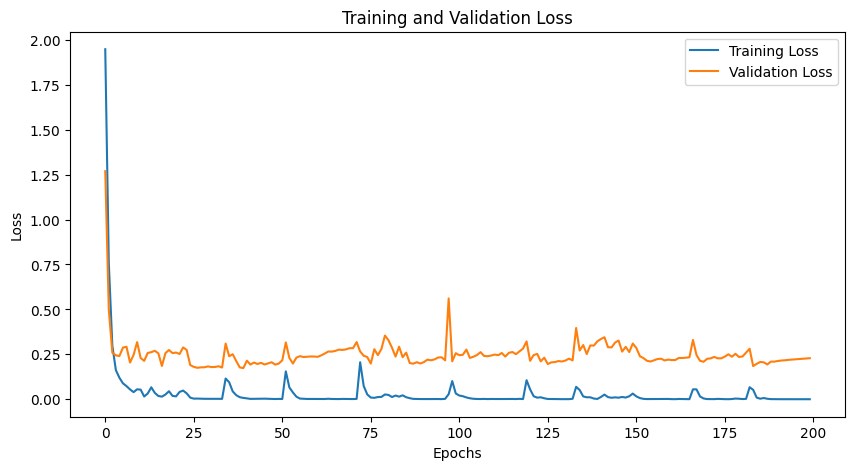

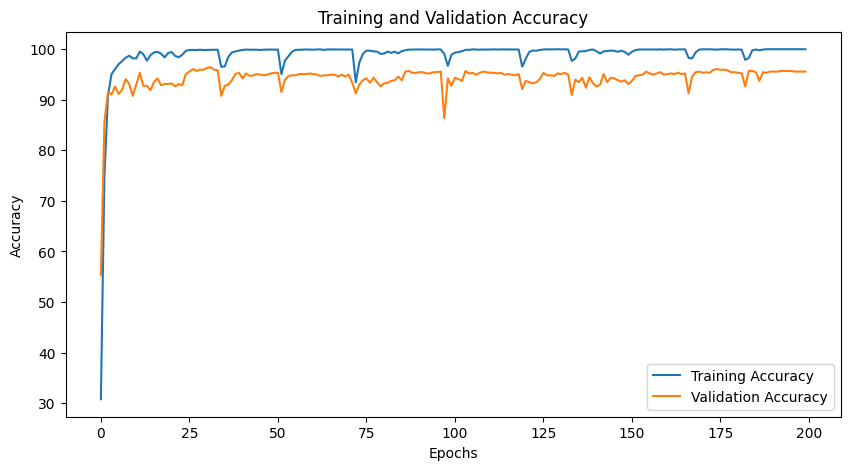

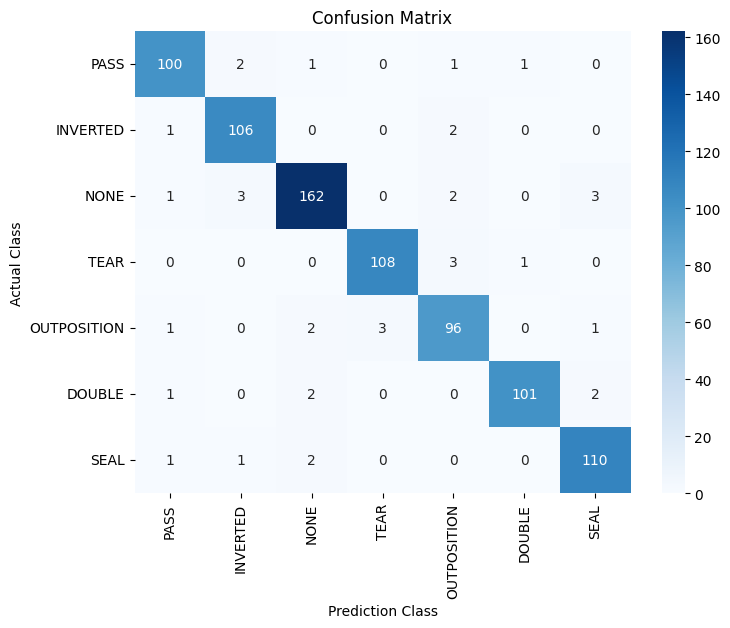

In [ ]:
plot_metrics(train_losses, val_losses, train_accuracies, val_accuracies, num_epochs=100)

plot_confusion_matrix(all_labels,all_preds,classes=['PASS','INVERTED','NONE','TEAR','OUTPOSITION','DOUBLE','SEAL'])

In [19]:
torch.save(model.state_dict(), "ViT_V2B08lr0001.pth")

In [ ]:
# Calculate metrics
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds, average='macro')
recall = recall_score(all_labels, all_preds, average='macro')
f1 = f1_score(all_labels, all_preds, average='macro')

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1 Score: {f1:.4f}")



In [30]:
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import numpy as np

# Example: Your dataset class, replace with your own
class YourTestDataset(torch.utils.data.Dataset):
    def __init__(self):
        # load your test data here
        pass

    def __len__(self):
        # return length of dataset
        pass

    def __getitem__(self, idx):
        # return a sample and label at index idx
        # Example: return image_tensor, label
        pass

# Load your model architecture - define the model class exactly as used when training
class YourModel(torch.nn.Module):
    def __init__(self):
        super(YourModel, self).__init__()
        # define your layers here

    def forward(self, x):
        # define forward pass
        pass

# Load the saved model
def load_model(path, device):
    model = YourModel()
    model.load_state_dict(torch.load(path, map_location=device))
    model.to(device)
    model.eval()
    return model

def evaluate(model, dataloader, device):
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            # Assuming outputs are logits, apply softmax or sigmoid depending on task
            if outputs.shape[1] == 1:  # binary classification
                preds = (torch.sigmoid(outputs) > 0.5).long()
            else:
                preds = torch.argmax(outputs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted')
    cm = confusion_matrix(all_labels, all_preds)

    print(f'Accuracy: {accuracy:.4f}')
    print(f'Precision: {precision:.4f}')
    print(f'Recall: {recall:.4f}')
    print(f'F1 Score: {f1:.4f}')
    print('Confusion Matrix:')
    print(cm)

def main():
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # Load test dataset and dataloader
    test_dataset = YourTestDataset()
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

    # Load model
    model_path = r'D:\Adrian Leong\Coding\ViT_V2B32lr0001.pth'
    model = load_model(model_path, device)

    # Evaluate
    evaluate(model, test_loader, device)

if __name__ == "__main__":
    main()

RuntimeError: Error(s) in loading state_dict for YourModel:
	Unexpected key(s) in state_dict: "pos_embedding", "cls_token", "to_patch_embedding.3.norm.weight", "to_patch_embedding.3.norm.bias", "to_patch_embedding.3.layers.0.0.norm.weight", "to_patch_embedding.3.layers.0.0.norm.bias", "to_patch_embedding.3.layers.0.0.to_qkv.weight", "to_patch_embedding.3.layers.0.1.net.0.weight", "to_patch_embedding.3.layers.0.1.net.0.bias", "to_patch_embedding.3.layers.0.1.net.1.weight", "to_patch_embedding.3.layers.0.1.net.1.bias", "to_patch_embedding.3.layers.0.1.net.4.weight", "to_patch_embedding.3.layers.0.1.net.4.bias", "to_patch_embedding.7.norm.weight", "to_patch_embedding.7.norm.bias", "to_patch_embedding.7.layers.0.0.norm.weight", "to_patch_embedding.7.layers.0.0.norm.bias", "to_patch_embedding.7.layers.0.0.to_qkv.weight", "to_patch_embedding.7.layers.0.1.net.0.weight", "to_patch_embedding.7.layers.0.1.net.0.bias", "to_patch_embedding.7.layers.0.1.net.1.weight", "to_patch_embedding.7.layers.0